<hr style="border:2px solid blue">

# CIS 454 - AI and Advanced Python
## Spring, 2026.  Univeristy of Maine at Augusta

<hr style="border:2px solid blue">


# Assignment 4 - Internet Data

In this assignment you will gain some hands-on experience using REST to retrieve JSON-formatted data from the internet and then converting that data to a useable form.   

Insipration for this Assignment came from [API Integeration in Python](https://realpython.com/api-integration-in-python/)


# Section 1, REST & JSON in Python

To get started, let's import the libaries we will need.    Hopefully you have `requests` and `json`; if not, add them to your environment.

In [1]:
import numpy as np
import pandas as pd

import matplotlib as plt
%matplotlib inline

import requests
import json

print(f'NumPy:      {np.__version__}')
print(f'Pandas:     {pd.__version__}')
print(f'matplotlib: {plt.__version__}')
print(f'Requests:   {requests.__version__}')
print(f'JSON:       {json.__version__}')


NumPy:      2.3.5
Pandas:     2.3.3
matplotlib: 3.10.6
Requests:   2.32.5
JSON:       2.0.9


## 1.1 Create your account

We're going to use a datasource from [rapidapi.com](http://rapidapi.com/hub), a site with lots of useful data sources. You will need to create a free account to work with the data at Rapid. 

## 1.2 Our first REST example

Our first RESTfull example is a simple one.  Say you are building a billing system for an international web site, and need current exchange data to properly disply the product cost in different countries.    Rather than maintain the exchange rate data, let's grab it off the Internet!

We will use the RapidAPI [ExchangeRate-API](https://rapidapi.com/exchangerateapi/api/exchangerate-api/), which is free (we like free!). 

### Define URL

We begin by defining the URL which provides access to our endpoint

In [2]:

requestURL = "https://exchangerate-api.p.rapidapi.com/rapid/latest/USD"



The url includes:
- `https://`   - the communication protocol
- `exchangerate-api.p.rapidapi.com` - the domain name for the service
- `/rapid/latest/USD` - the REST endpoint.   In this case, the `USD` is a parameter being passed to specify that we want exchange rates for converting to US Dollars

Now, it's frequently the case that a REST API will receive and process header parameters.  RapdiAPI expects two parameters for the call -- the host and the authentication key associated with your account.    They are specified as key:value pairs in a dictionary.   


You will need to fetch your authentication key from the RapidAPI web site.   Visit the [page for the exchange rate API](https://rapidapi.com/exchangerateapi/api/exchangerate-api/) and click on `Go to Playground`.  On the code snippet tile (on the right), set the language to Python, and the protocol to requests.   You will see something like this:

```
headers = {
	"x-rapidapi-key": "aVeryVeryLongSequenceOfLettersAndNumbers0123456789",
	"x-rapidapi-host": "exchangerate-api.p.rapidapi.com"
}
```

Copy the `x-rapidapi-key` it displays for your account and fill in the cell below.

In [6]:
myRapidAPIKey = "c7d06bfcc2msh28ace618841f8acp19aaf0jsn6960007eeec6"

In [7]:
headers = {
    'x-rapidapi-key': myRapidAPIKey, 
    'x-rapidapi-host': "exchangerate-api.p.rapidapi.com"
}


### Make REST API Request

OK, with the URL and headers defined, let's  make our RESTfull call.    As REST uses HTTP as it's underlying network transport protocol.  We will use the Python `requests` library to make our call.   

In [8]:

response = requests.request("GET", requestURL, headers=headers)



Did it work?   Well, we don't quite know yet.   Let's look at response.  What type of data is it?

In [9]:
print(type(response))

<class 'requests.models.Response'>



Oooh, it's an instance of the class `requests.models.Response` --I wonder what attributes it has?   Python has a built-in command, `dir` (short for directory), which lists the attributes (instance variable and method names) of an object.

In [10]:
dir(response)

['__attrs__',
 '__bool__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__enter__',
 '__eq__',
 '__exit__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__iter__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__nonzero__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_content',
 '_content_consumed',
 '_next',
 'apparent_encoding',
 'close',
 'connection',
 'content',
 'cookies',
 'elapsed',
 'encoding',
 'headers',
 'history',
 'is_permanent_redirect',
 'is_redirect',
 'iter_content',
 'iter_lines',
 'json',
 'links',
 'next',
 'ok',
 'raise_for_status',
 'raw',
 'reason',
 'request',
 'status_code',
 'text',
 'url']

My guess is that the methods are all prefaced with leading underscores; the others are varaibles.   `status_code` looks interesting.   Let's check it out

In [11]:
print(response.status_code)


200


A status code of **200** is good - that's the success code for HTTP calls.  We made a successful call.   

### Process the response to get our resource

Now, where is out data?    maybe in `json` ?

In [12]:
print(response.json)

<bound method Response.json of <Response [200]>>


A bound method?   Ah, tricky object!  Let's add parenthesis and call the method.

In [13]:
print(response.json())

{'result': 'success', 'provider': 'https://www.exchangerate-api.com', 'documentation': 'https://www.exchangerate-api.com/docs/free', 'terms_of_use': 'https://www.exchangerate-api.com/terms', 'time_last_update_unix': 1774656151, 'time_last_update_utc': 'Sat, 28 Mar 2026 00:02:31 +0000', 'time_next_update_unix': 1774744381, 'time_next_update_utc': 'Sun, 29 Mar 2026 00:33:01 +0000', 'time_eol_unix': 0, 'base_code': 'USD', 'rates': {'USD': 1, 'AED': 3.6725, 'AFN': 63.70309, 'ALL': 82.997361, 'AMD': 377.260843, 'ANG': 1.79, 'AOA': 922.065362, 'ARS': 1376.0989, 'AUD': 1.453841, 'AWG': 1.79, 'AZN': 1.700272, 'BAM': 1.697935, 'BBD': 2, 'BDT': 122.728589, 'BGN': 1.697935, 'BHD': 0.376, 'BIF': 2979.243996, 'BMD': 1, 'BND': 1.287609, 'BOB': 6.931637, 'BRL': 5.240099, 'BSD': 1, 'BTN': 94.816985, 'BWP': 14.031222, 'BYN': 2.969424, 'BZD': 2, 'CAD': 1.387485, 'CDF': 2291.748711, 'CHF': 0.797804, 'CLF': 0.023446, 'CLP': 926.772997, 'CNH': 6.916355, 'CNY': 6.919822, 'COP': 3701.661272, 'CRC': 466.02222

Better!   We have some json data to play with.    That looks alot like a python dictionary, doesn't it?   I wonder, just what does this `json()` method do?    Let's save the results to a new variable and inspect it's data type.

In [14]:
ratedata = response.json()
print(type(ratedata))

<class 'dict'>


We have a dictionary!     Let's look at the keys.

In [15]:
for key in ratedata.keys():
    print(key)

result
provider
documentation
terms_of_use
time_last_update_unix
time_last_update_utc
time_next_update_unix
time_next_update_utc
time_eol_unix
base_code
rates


`rates` -- we're getting close!  Let's grab the value associated with the key `rates` from the `ratedata` dictionary.

In [16]:
rates = ratedata['rates']
print(type(rates))

<class 'dict'>


Ah, `rates` is itself a dictionary.   That makes sense - very easy to look up the exchange rate for an individual country.  Let's see what our dictionary holds

In [17]:
for key, value in rates.items():
    print(f'{key}, {value}')

USD, 1
AED, 3.6725
AFN, 63.70309
ALL, 82.997361
AMD, 377.260843
ANG, 1.79
AOA, 922.065362
ARS, 1376.0989
AUD, 1.453841
AWG, 1.79
AZN, 1.700272
BAM, 1.697935
BBD, 2
BDT, 122.728589
BGN, 1.697935
BHD, 0.376
BIF, 2979.243996
BMD, 1
BND, 1.287609
BOB, 6.931637
BRL, 5.240099
BSD, 1
BTN, 94.816985
BWP, 14.031222
BYN, 2.969424
BZD, 2
CAD, 1.387485
CDF, 2291.748711
CHF, 0.797804
CLF, 0.023446
CLP, 926.772997
CNH, 6.916355
CNY, 6.919822
COP, 3701.661272
CRC, 466.022222
CUP, 24
CVE, 95.725523
CZK, 21.286188
DJF, 177.721
DKK, 6.479661
DOP, 60.401687
DZD, 132.722332
EGP, 52.745937
ERN, 15
ETB, 155.27097
EUR, 0.868142
FJD, 2.247426
FKP, 0.752793
FOK, 6.479659
GBP, 0.752795
GEL, 2.699766
GGP, 0.752793
GHS, 11.020442
GIP, 0.752793
GMD, 74.18787
GNF, 8767.130045
GTQ, 7.658996
GYD, 209.221548
HKD, 7.832649
HNL, 26.54859
HRK, 6.541005
HTG, 131.19273
HUF, 337.776619
IDR, 16962.363336
ILS, 3.14728
IMP, 0.752793
INR, 94.834734
IQD, 1310.382788
IRR, 1153558.127907
ISK, 124.64324
JEP, 0.752793
JMD, 158.04799


And there you go - we just fetched the exchange rates for currencies off the internet, and it's in a dictionary we can use inside our program.  For example, if you want to know the current value of a dollar in Euros, we could use:


In [18]:
print(f'A Dollar is currently worth {rates["EUR"]} Euros')

A Dollar is currently worth 0.868142 Euros



The takeaway?  JSON naturally lends itself to conversion to a Python dictionary, where the attribute-value pairs translate to key-value pairs. There's typically a lot of nesting going on -- we went from `ratedata` to `rates` to the rates for the individual country codes. Learning how to work with a new API is mostly an effort in navigating down through the returned values, whether they be dictionaries or lists.

The vast amount of data available on the internet is now at your fingertips.



## 1.3 Another API, Stock Market Data

Here's a more interesting example.

Yahoo Finance maintains a history of stock prices, and there are handfulls of APIs to gain access.    We'll use a simple one from RapidAPI, [Yahhoo Finance by API Datacenter](https://rapidapi.com/sparior/api/yahoo-finance15) to explore some stock price trends.  You should visit that site and add it to the subscriptions for your RapidAPI account.

NVidia is one of the big stocks these days.  Let's grabs its' historical data, convert it to a Pandas dataframe, and plot it. We are going to use the `stock/ve/get-historical-data` API to grab the prior five years of monthly history.

Now, this API requires a set of parameters in the call.   We create those as a `querystring` dictionary, and pass them along using the `params=` parameter to our `request.request` call.



In [25]:
url = "https://yahoo-finance15.p.rapidapi.com/api/v1/markets/stock/history"

querystring = {"symbol":"NVDA","interval":"1wk","diffandsplits":"false"}

headers = {
	"X-RapidAPI-Key": myRapidAPIKey,   # again, you will need your key here
	"X-RapidAPI-Host": "yahoo-finance15.p.rapidapi.com"
}

response = requests.get(url, headers=headers, params=querystring)

print(response.status_code)


200


Did you see status code 200?  Good.

Let's take a look at the JSON.

In [26]:
stockdata = response.json()
print(type(stockdata))

<class 'dict'>


Another dictionary.  Not really a surprise.   What does it have for keys?

In [27]:
print(stockdata.keys())

dict_keys(['meta', 'body'])


Hmm, I wonder what `meta` holds

In [28]:
for key, value in stockdata['meta'].items():
    print(key, value)

processedTime 2026-03-28T20:56:28.965007Z
currency USD
symbol NVDA
exchangeName NMS
fullExchangeName NasdaqGS
instrumentType EQUITY
firstTradeDate 917015400
regularMarketTime 1774641600
hasPrePostMarketData True
gmtoffset -14400
timezone EDT
exchangeTimezoneName America/New_York
regularMarketPrice 167.52
fiftyTwoWeekHigh 212.19
fiftyTwoWeekLow 86.62
regularMarketDayHigh 170.97
regularMarketDayLow 167.01
regularMarketVolume 194056113
longName NVIDIA Corporation
shortName NVIDIA Corporation
chartPreviousClose 12.839
priceHint 2
dataGranularity 1wk
range 
version v1.0
status 200
copywrite https://steadyapi.com


OK, that looks like metadata describing what was returned. I suspect the values in `body` will be more useful.   Let's see:

In [29]:
print(stockdata['body'])

{'1616990400': {'date': '2021-03-29', 'date_utc': 1616990400, 'open': 12.82, 'high': 13.87, 'low': 12.7, 'close': 13.81, 'volume': 1096776000, 'adjclose': 13.78}, '1617595200': {'date': '2021-04-05', 'date_utc': 1617595200, 'open': 13.87, 'high': 14.47, 'low': 13.71, 'close': 14.4, 'volume': 1138288000, 'adjclose': 14.36}, '1618200000': {'date': '2021-04-12', 'date_utc': 1618200000, 'open': 14.29, 'high': 16.21, 'low': 14.14, 'close': 15.91, 'volume': 2864724000, 'adjclose': 15.87}, '1618804800': {'date': '2021-04-19', 'date_utc': 1618804800, 'open': 15.54, 'high': 15.81, 'low': 14.78, 'close': 15.27, 'volume': 1460616000, 'adjclose': 15.23}, '1619409600': {'date': '2021-04-26', 'date_utc': 1619409600, 'open': 15.19, 'high': 15.67, 'low': 15, 'close': 15.01, 'volume': 946892000, 'adjclose': 14.97}, '1620014400': {'date': '2021-05-03', 'date_utc': 1620014400, 'open': 15.13, 'high': 15.25, 'low': 14.01, 'close': 14.81, 'volume': 1323968000, 'adjclose': 14.78}, '1620619200': {'date': '202

This looks like a dictionary of dictionaries.  Let's look at just the first entry.

Here's a tricky line of Python syntax.    The `.items()` method is used to iterate through the key:value pairs of a dictionary.  We wrap that with the iter() method to create an iterator, and wrap that with the next() method to return the first key:value pair in the iterator.

In [30]:
print(next( iter( stockdata['body'].items() ) ) )

('1616990400', {'date': '2021-03-29', 'date_utc': 1616990400, 'open': 12.82, 'high': 13.87, 'low': 12.7, 'close': 13.81, 'volume': 1096776000, 'adjclose': 13.78})


OK, it seems like the value is a dictionary of key/value pairs which represent different statistics for that date.  We can work with this.

Pandas is great at handling a sequence of dictionaries.   It treats the key as the column heading, and creates a nice 2-D table for us.    Let's give it a try.

In [32]:
stockprice = pd.DataFrame(stockdata['body'].values())

Did it work?

In [33]:
stockprice.head()

,date,date_utc,open,high,low,close,volume,adjclose
0,2021-03-29,1616990400,12.82,13.87,12.70,13.81,1096776000,13.78
1,2021-04-05,1617595200,13.87,14.47,13.71,14.40,1138288000,14.36
2,2021-04-12,1618200000,14.29,16.21,14.14,15.91,2864724000,15.87
3,2021-04-19,1618804800,15.54,15.81,14.78,15.27,1460616000,15.23
4,2021-04-26,1619409600,15.19,15.67,15.00,15.01,946892000,14.97


Nice.    Looks like we have weekly price and trading data.  

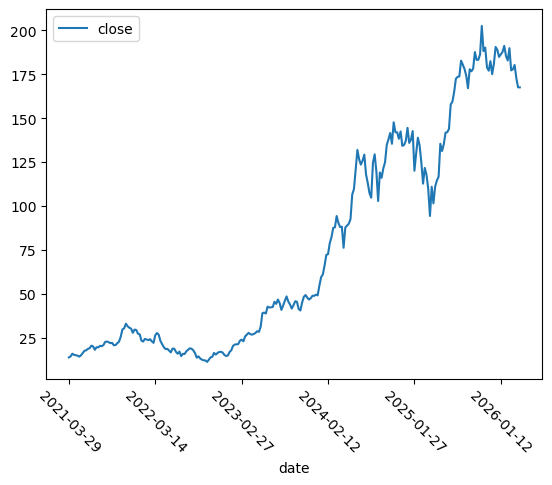

In [34]:
stockprice.plot(x='date', y='close', kind = 'line', rot=-45)
plt.pyplot.show()

If you bought way back in 2021 you are pretty happy, huh?

Let's make a more interesting one which shows both the closing price and the daily volume.

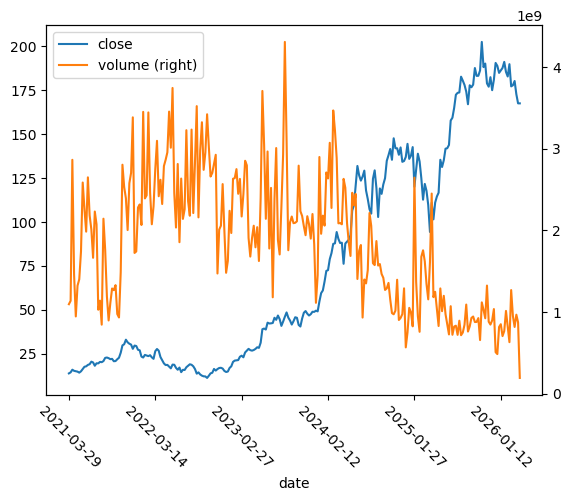

In [35]:
stockprice.plot(x='date', y=['close','volume'], secondary_y=['volume'],rot=-45) 

plt.pyplot.show()


Notice any interesting patterns in the data?   Can you correlate big volume days wth big changes in the stock price?  The possibilities for exploring information like this are endless.



So there's your introduction to working with REST servcies on the internet.   Now you get to put these techniques to use.


# Section 2, Independant Data Exploration

OK, now that you've seen the basics, here's your chance to build an interesting REST call.  There are a fair number of useful sites out there -- healthcase data, govenment data, sports & entertainment, just about anything you can imagine.   There are even REST APIs which allow you to take advantage of remote functionality like image capture and joke generation. Here's a few sites worth checking out:

- [RapidAPI](https://rapidapi.com/hub)
- [A Twitter Social Feed on RapidAPI](https://rapidapi.com/sparior/api/twitter-social)
- [15 Fun and Interesting APIS](https://medium.com/codex/15-fun-and-interesting-apis-to-use-for-your-next-coding-project-in-2022-86a4ff3a2742)
- [NASA APIs](https://api.nasa.gov/index.html)
- [Opensource GitHub of  public-APIs](https://github.com/public-apis/public-apis?tab=readme-ov-file)


Your taks is to find a REST API you find interesting, build out the request, explore the response, and do something usefull with the resource returned. Please be sure to embed any required key/credential in your notebook so that I may recreate your results.

Be creative. And have fun!

## My Outline

While it may be somewhat hard, I've loved space for so long that I can't resist working with one of the NASA APIs.

For this assignment, my intention is to use NASA's NeoWs API regarding near earth objects and train a classification model to predict whether an asteroid may be potentially hazardous given the parameters accessed through the API calls. I will first review the data format, converting the JSON data into a Pandas Data Frame, use pandas to pre-process the data, and then train a Random Forest classifier to predict the value of the boolean: is_potentially_hazardous_asteroid

I envision this being potentially useful potentially for asteroid researchers who may want to quickly identify high-risk asteroids to inspect with greater priority. I am not entirely sure how NASA assesses the threat of any given asteroid, but I envision that it involves computationally intensive physics simulations that would take a long time. Therefore, this classification model I could see as a tool to identify asteroids to focus on first.

### Step 1

The first thing I need to do is fetch all the data. For this step, I created an account, and reviewed the APIs rate limits 

**Note: The limits are SLOW, this will take up to 10 mins to run**

In [155]:
# This is the API key I was given. I wonder why they are so long. Even for encryption standards, this is crazy:
NASA_API_KEY = "aBLtIXAeQp9KQpCltagDp3T8qL8MLYCn7T8um2ar"

In [96]:
# configure the URL and all the parameters. Page: 0 pretty much means "start at page 0"; size means 
# "return 20 asteroids to each request, which is the limit.
asteroids = []
url = "https://api.nasa.gov/neo/rest/v1/neo/browse"
params = {"api_key": NASA_API_KEY, "page": 0, "size": 20}

# Create where the data will be stored to, and save the total number of pages for the request loop
NASA_response = requests.get(url, params=params).json()
asteroids.extend(response["near_earth_objects"])
total_pages = response["page"]["total_pages"]

# Loop over the last 500 pages (~10000 asteroids). I would love to do more, but there are rate limits,
# and there are also limits to the total amount of data you can request per day. Therefore, I didn't 
# want to request too much, find a bug, and then have to create a new API key.
for page in range(total_pages - 500, total_pages):
    params["page"] = page
    response = requests.get(url, params=params).json()
    asteroids.extend(response["near_earth_objects"])
    print(f"Retrieved Page {page + 1} of {total_pages}", end="\r")

print(f"\nTotal asteroids: {len(asteroids)}")

Retrieved Page 2139 of 2139
Total asteroids: 10002


Now that I have a list with all the asteroids, I want to take a look at some of the data. 

Note: I didn't include all tests, but I did include all the ones I got the important information from.

In [101]:
# Look at the keys. 
print(asteroids[0].keys())

dict_keys(['links', 'id', 'neo_reference_id', 'name', 'designation', 'nasa_jpl_url', 'absolute_magnitude_h', 'estimated_diameter', 'is_potentially_hazardous_asteroid', 'close_approach_data', 'orbital_data', 'is_sentry_object'])


In [98]:
# Look at the structure (this took a while to sift through, I probably could have done it more efficiently, 
# but it worked out in the end)
print(asteroids[0])

{'links': {'self': 'http://api.nasa.gov/neo/rest/v1/neo/54375698?api_key=aBLtIXAeQp9KQpCltagDp3T8qL8MLYCn7T8um2ar'}, 'id': '54375698', 'neo_reference_id': '54375698', 'name': '(2023 OC1)', 'designation': '2023 OC1', 'nasa_jpl_url': 'https://ssd.jpl.nasa.gov/tools/sbdb_lookup.html#/?sstr=54375698', 'absolute_magnitude_h': 23.86, 'estimated_diameter': {'kilometers': {'estimated_diameter_min': 0.04493192, 'estimated_diameter_max': 0.1004708274}, 'meters': {'estimated_diameter_min': 44.9319199631, 'estimated_diameter_max': 100.470827397}, 'miles': {'estimated_diameter_min': 0.027919392, 'estimated_diameter_max': 0.0624296585}, 'feet': {'estimated_diameter_min': 147.4144402917, 'estimated_diameter_max': 329.6287093572}}, 'is_potentially_hazardous_asteroid': False, 'close_approach_data': [{'close_approach_date': '2021-01-02', 'close_approach_date_full': '2021-Jan-02 11:02', 'epoch_date_close_approach': 1609585320000, 'relative_velocity': {'kilometers_per_second': '10.6486324121', 'kilometers

### Step 2

Now having looked at how the data is structured, it's time to convert it into a Pandas data frame. This is pretty
easy to do at this point, as I feel like I've done this 100 times by now. I like being at that point, as it feels like it
means I will be far more comfortable using Pandas in the future.

In [188]:
rows = []
for a in asteroids:
    # This was the only weird one, I just took the closest it has ever come
    cad = min(a["close_approach_data"], key=lambda x: float(x["miss_distance"]["kilometers"]), default={})

    # The only data that could potentially have None is accounted for. However, when manually importing like this, it is
    # important to be vigilant about. I got a couple of errors the first time around because there were a few missing data points
    # I didn't account for.

    # Also note that there are a few pieces of data that might matter, but I viewed these as the most significant. The accuracy turned out to be 
    # really good anyway!
    rows.append({
        "id": a["id"],
        "name": a["name"],
        "is_hazardous": int(a["is_potentially_hazardous_asteroid"]),
        "absolute_magnitude": a.get("absolute_magnitude_h", None),
        "est_diameter_min_km": a.get("estimated_diameter", {}).get("kilometers", {}).get("estimated_diameter_min", None),
        "est_diameter_max_km": a.get("estimated_diameter", {}).get("kilometers", {}).get("estimated_diameter_max", None),
        "relative_velocity_km_s": float(cd.get("relative_velocity", {}).get("kilometers_per_second", 0)),
        "miss_distance_km": float(cad.get("miss_distance", {}).get("kilometers", 0))
    })

# Get rid of any duplicate asteroids and display the first few just to check things. It should look nice.
df = pd.DataFrame(rows).drop_duplicates().reset_index()
df.head()

,index,id,name,is_hazardous,absolute_magnitude,est_diameter_min_km,est_diameter_max_km,relative_velocity_km_s,miss_distance_km
0,0,54375698,(2023 OC1),0,23.86,0.044932,0.100471,13.068517,2.044620e+07
1,1,54375699,(2023 OD1),0,24.85,0.028481,0.063685,13.068517,3.298243e+06
2,2,54375702,(2023 OE1),0,27.17,0.009785,0.021880,13.068517,7.664325e+05
3,3,54375703,(2023 OF1),0,24.87,0.028220,0.063102,13.068517,6.795548e+06
4,4,54375704,(2023 OJ1),0,26.12,0.015869,0.035485,13.068517,5.349263e+05


In good practice, I want to check for null data:

In [180]:
# See if there is any null data
df.isnull().sum()

index                     0
id                        0
name                      0
is_hazardous              0
absolute_magnitude        1
est_diameter_min_km       1
est_diameter_max_km       1
relative_velocity_km_s    0
miss_distance_km          0
dtype: int64

Alright, there are a few with null data. However, as it is so few, I will just remove them:

In [181]:
# Drop it and check again
df = df.dropna()
df.isnull().sum()

index                     0
id                        0
name                      0
is_hazardous              0
absolute_magnitude        0
est_diameter_min_km       0
est_diameter_max_km       0
relative_velocity_km_s    0
miss_distance_km          0
dtype: int64

### Step 3

It's machine learning time! I will be referencing a lot of the code from the previous assignment, so that is why there aren't as many source links. However, I will reference all the links I used last time, which are as follows:

In [182]:
# Separating training vs test data is important, which logically makes it the first step

from sklearn.model_selection import train_test_split

# name, id, and is_hazardous should not be included for training, so I selected only the valid training features
features = [
    "absolute_magnitude",
    "est_diameter_min_km",
    "est_diameter_max_km",
    "relative_velocity_km_s",
    "miss_distance_km"
]

x = df[features]
y = df["is_hazardous"]

# Split!
x_train,x_validate,y_train,y_validate=train_test_split(x,y,test_size=0.2,random_state=123456)

Now, I just wanted to see what everything looks like.

In [117]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7984 entries, 2349 to 6210
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   absolute_magnitude      7984 non-null   float64
 1   est_diameter_min_km     7984 non-null   float64
 2   est_diameter_max_km     7984 non-null   float64
 3   relative_velocity_km_s  7984 non-null   float64
 4   miss_distance_km        7984 non-null   float64
dtypes: float64(5)
memory usage: 374.2 KB


In [118]:
x_validate.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1997 entries, 361 to 857
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   absolute_magnitude      1997 non-null   float64
 1   est_diameter_min_km     1997 non-null   float64
 2   est_diameter_max_km     1997 non-null   float64
 3   relative_velocity_km_s  1997 non-null   float64
 4   miss_distance_km        1997 non-null   float64
dtypes: float64(5)
memory usage: 93.6 KB


In [119]:
y_train.value_counts()

is_hazardous
0    7706
1     278
Name: count, dtype: int64

In [120]:
y_validate.value_counts()

is_hazardous
0    1925
1      72
Name: count, dtype: int64

Now, it's finally time to initialize the random forest classifier.

While I didn't anticipate using any other sources, I realized something important. Identifying hazardous asteroids correctly is far more important that identifying non-hazardous asteroids correctly. Therefore, I looked up how to weight the classifier to heavily punish incorrectly identified hazardous asteroids. You can see this in the "class_weight" parameter, where identifying hazardous asteroids correctly I weighted as 50x more important from trial and error. Here are my sources:

https://www.geeksforgeeks.org/machine-learning/how-does-the-classweight-parameter-in-scikit-learn-work/

https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html

In [183]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the classifier. I used largely the same parameters from the last assignment.
AsteroidRF = RandomForestClassifier(
    n_estimators=150,       
    max_depth=16,           
    min_samples_split=25,    
    min_samples_leaf=8,
    random_state=314159,   
    class_weight = {0: 1, 1: 50}, # See markup above
    n_jobs=-1 
)

AsteroidRF.fit(x_train, y_train)

,n_estimators,150
,criterion,'gini'
,max_depth,16
,min_samples_split,25
,min_samples_leaf,8
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [184]:
y_predict = AsteroidRF.predict(x_validate)

### Step 4

Now that the model has been trained, time to take a look at some statistics.

In [185]:
# Test accuracy 
# Note: This accuracy would be FAR higher if I didn't weight the hazardous asteroids more (around 97-99%).
# However, the accuracy for hazardous asteroid identification is much better.

print(f'Overall accuracy against training data is {AsteroidRF.score(x_train, y_train):5.2%}')
print(f'Overall accuracy against validation data is {AsteroidRF.score(x_validate, y_validate):5.2%}')

from sklearn.metrics import classification_report
print(classification_report(y_validate, y_predict))

Overall accuracy against training data is 92.99%
Overall accuracy against validation data is 91.44%
              precision    recall  f1-score   support

           0       0.99      0.92      0.95      1925
           1       0.27      0.83      0.41        72

    accuracy                           0.91      1997
   macro avg       0.63      0.88      0.68      1997
weighted avg       0.97      0.91      0.93      1997



In [186]:
# This communicates a more complete story of why this may be used. While there are some incorrect predictions, 
# by and large, the weighting on the hazardous asteroids had a really profound effect.

pd.set_option("display.max_rows", 75)
comparison = pd.DataFrame({"actual": y_validate, "predicted": y_predict})
comparison[comparison["actual"] == 1]

,actual,predicted
6121,1,1
4095,1,0
348,1,1
3017,1,1
306,1,1
4914,1,1
7915,1,0
5002,1,1
9381,1,1
5509,1,0


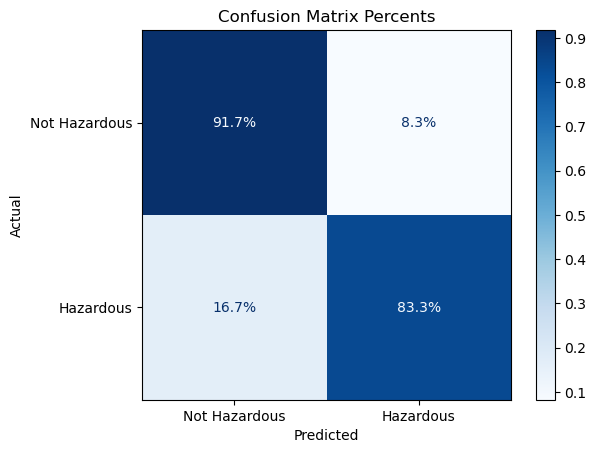

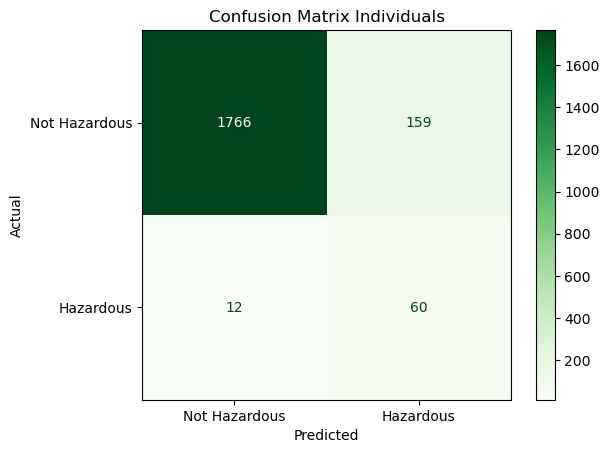

In [187]:
# Have you ever seen a confusion matrix? I assume so, but when I was looking for good ways to visualize data,
# this really stuck out to me. Pretty much (ONLY FOR PERCENTS), the diagonals should be as dark as possible, and the off-diagonals
# should be as white as possible. The fact that the bottom left square is darker than the top right is an effect
# created by the weighting done earlier; there are far fewer incorrect hazardous predictions.

# For the numeric one, this is just a way of displaying the numbers in all the categories. I will also add that I already knew
# about this type of graph from when I did the M3 Junior Challenge. 

# Sources:

# https://www.geeksforgeeks.org/machine-learning/how-to-plot-confusion-matrix-with-labels-in-sklearn/
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create two confusion matrices, one for the percentages, one to show the samples/individuals

cm = confusion_matrix(y_validate, y_predict, normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Hazardous", "Hazardous"])
disp.plot(cmap="Blues", values_format=".1%")
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
plt.title("Confusion Matrix Percents")
plt.show()

cm = confusion_matrix(y_validate, y_predict)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Hazardous", "Hazardous"])
disp.plot(cmap="Greens")
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
plt.title("Confusion Matrix Individuals")
plt.show()


## Conclusion

And that's it.   I hope you enjoyed this introduciton to JSON & REST.   Please upload your Jupyter notebook to BrightSpace and be sure to update your GIT repository.


## Personal Write-Up

This was a lot of fun! Maybe I went a tad overkill by implementing AI, but I thought it was really fun to work on. This is the first time that I've decided to program something that felt entirely unique, and resulted in something that turned out to be really accurate and effective at what I was trying to do. I envision that this would only become more accurate if you were to introduce more data, which is great considering how accurate it already is. 

Anyway, I had a lot of fun with this!